# Naranjas: comparación de arquitecturas (YOLOv8n-seg, YOLO11n-seg, YOLO26n-seg) × 3 semillas

Complementa `naranjas.ipynb`. Se entrenan **tres arquitecturas distintas** de segmentación con la misma receta
(mismo dataset filtrado a naranjas, 30 épocas, 640 px, batch 16) y **tres semillas** cada una, para reportar
media ± desviación. También se mide cada arquitectura **sin entrenar** (preentrenada en COCO, clase 49).

Todo queda en `MyDrive/naranjas/`:

```
dataset/        estadísticas del dataset (imagenes.csv, objetos.csv, README de Roboflow, muestras.jpg)
arquitecturas/  estructura de cada modelo, entrenamientos (runs/), validaciones (val/) y metricas_test.csv
```

**Antes de ejecutar:** *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*, y el secreto `ROBOFLOW_API_KEY`
con acceso del notebook activado (🔑 en la barra izquierda).

Si Colab se desconecta, volvé a ejecutar todo: los entrenamientos terminados se saltean y el que quedó a medias se retoma.

In [6]:
# 1. GPU, librerías y Drive
!pip install -q ultralytics roboflow

import torch

if not torch.cuda.is_available():
    raise RuntimeError('No hay GPU: Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU')
print('GPU:', torch.cuda.get_device_name(0))

from google.colab import drive

drive.mount('/content/drive')

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


loading Roboflow workspace...
loading Roboflow project...
===== README.roboflow.txt =====

Orange occlusion dataset - v5 2025-03-16 10:48pm

This dataset was exported via roboflow.com on October 21, 2026 at 5:22 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 1000 images.
Orange-leaf-branch are annotated in YOLOv8 format.

The following pre-processing was applied to each image:
* Auto-orientation of pixel data (with EXIF-orientation stripping)
* Resi

,imagenes,leafs,oranges,sin_naranjas,resoluciones
split,,,,,
test,100,1019,390,2,640x640
train,700,6748,2574,0,640x640
val,200,1903,785,1,640x640


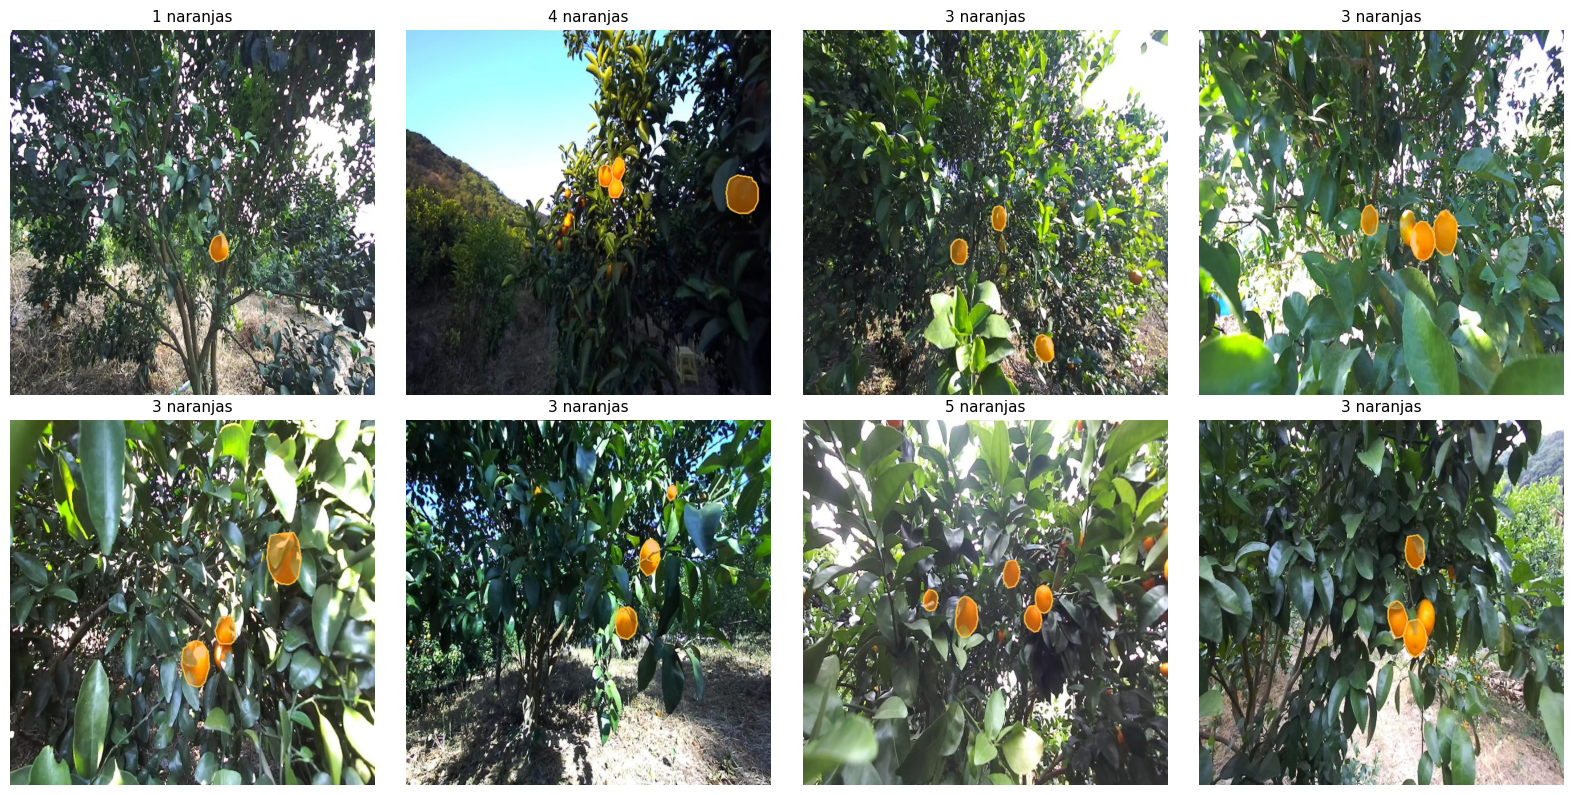

In [7]:
# 2. Dataset: descarga, copia solo con naranjas (clase 0) y estadísticas para la presentación
import json
import shutil
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from google.colab import userdata
from IPython.display import display
from roboflow import Roboflow

DRIVE_DIR = Path('/content/drive/MyDrive/naranjas')
DS_DIR = DRIVE_DIR / 'dataset'
ARQ_DIR = DRIVE_DIR / 'arquitecturas'
for d in (DS_DIR, ARQ_DIR):
    d.mkdir(parents=True, exist_ok=True)
WORK_DIR = Path('/content')
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
dataset = (rf.workspace('canerbeldek').project('orange-occlusion-dataset').version(5)
           .download('yolov8', location=str(WORK_DIR / 'orange-occlusion')))
ORIGEN_DIR = Path(dataset.location)

original = yaml.safe_load((ORIGEN_DIR / 'data.yaml').read_text())
nombres = original['names']
CLASES_ORIGEN = dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}
ID_NARANJA = next(k for k, v in CLASES_ORIGEN.items() if v.lower() == 'orange')
SPLITS = {'train': 'train', 'val': 'valid', 'test': 'test'}

for readme in ORIGEN_DIR.glob('README*'):
    shutil.copy(readme, DS_DIR / readme.name)
    print(f'===== {readme.name} =====\n{readme.read_text()}\n')


def area_poligono(xy):
    """Área de un polígono normalizado (fracción de la imagen), fórmula del cordón de zapato."""
    x, y = xy[:, 0], xy[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))


DATASET_DIR = WORK_DIR / 'orange-solo'
shutil.rmtree(DATASET_DIR, ignore_errors=True)
filas_img, filas_obj = [], []
for split, carpeta in SPLITS.items():
    shutil.copytree(ORIGEN_DIR / carpeta / 'images', DATASET_DIR / carpeta / 'images')
    (DATASET_DIR / carpeta / 'labels').mkdir(parents=True)
    for img in sorted(p for p in (ORIGEN_DIR / carpeta / 'images').iterdir() if p.suffix.lower() in IMG_EXT):
        alto, ancho = cv2.imread(str(img)).shape[:2]
        txt = ORIGEN_DIR / carpeta / 'labels' / f'{img.stem}.txt'
        lineas = txt.read_text().splitlines() if txt.exists() else []
        naranjas, n_por_clase = [], {v: 0 for v in CLASES_ORIGEN.values()}
        for linea in lineas:
            v = linea.split()
            if len(v) < 5:
                continue
            clase = int(v[0])
            coords = np.array(v[1:], dtype=float)
            n_por_clase[CLASES_ORIGEN[clase]] += 1
            xy = coords.reshape(-1, 2) if len(coords) > 4 else None
            if xy is not None:
                x0, y0, x1, y1 = xy[:, 0].min(), xy[:, 1].min(), xy[:, 0].max(), xy[:, 1].max()
                filas_obj.append({'split': split, 'imagen': img.name, 'clase': CLASES_ORIGEN[clase],
                                  'vertices': len(xy), 'area_rel': area_poligono(xy),
                                  'ancho_rel': x1 - x0, 'alto_rel': y1 - y0,
                                  'cx': (x0 + x1) / 2, 'cy': (y0 + y1) / 2})
            if clase == ID_NARANJA:
                naranjas.append(' '.join(['0', *v[1:]]))
        (DATASET_DIR / carpeta / 'labels' / f'{img.stem}.txt').write_text('\n'.join(naranjas))
        filas_img.append({'split': split, 'imagen': img.name, 'ancho': ancho, 'alto': alto,
                          **{f'n_{k}': n for k, n in n_por_clase.items()}})

imagenes_df = pd.DataFrame(filas_img)
objetos_df = pd.DataFrame(filas_obj)
imagenes_df.to_csv(DS_DIR / 'imagenes.csv', index=False)
objetos_df.to_csv(DS_DIR / 'objetos.csv', index=False)

DATA_YAML = DATASET_DIR / 'data_local.yaml'
DATA_YAML.write_text(yaml.safe_dump({
    'path': str(DATASET_DIR), 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
    'names': {0: 'orange'},
}))
TEST_IMAGES = DATASET_DIR / 'test' / 'images'

resumen_ds = imagenes_df.groupby('split').agg(
    imagenes=('imagen', 'count'),
    **{f'{k}s': (f'n_{k}', 'sum') for k in CLASES_ORIGEN.values()},
    sin_naranjas=(f'n_{CLASES_ORIGEN[ID_NARANJA]}', lambda s: int((s == 0).sum())),
    resoluciones=('ancho', lambda s: ', '.join(sorted({f'{a}x{h}' for a, h in zip(s, imagenes_df.loc[s.index, 'alto'])}))),
)
resumen_ds.to_csv(DS_DIR / 'resumen_dataset.csv')
display(resumen_ds)

# Muestras con las naranjas etiquetadas, para la diapositiva del dataset
muestras = sorted((DATASET_DIR / 'train' / 'images').iterdir())[:8]
fig, ejes = plt.subplots(2, 4, figsize=(16, 8))
for eje, img in zip(ejes.flat, muestras):
    rgb = cv2.cvtColor(cv2.imread(str(img)), cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    capa = rgb.copy()
    lineas = (DATASET_DIR / 'train' / 'labels' / f'{img.stem}.txt').read_text().splitlines()
    for linea in lineas:
        pts = (np.array(linea.split()[1:], dtype=float).reshape(-1, 2) * [w, h]).astype(np.int32)
        cv2.fillPoly(capa, [pts], (255, 140, 0))
        cv2.polylines(rgb, [pts], True, (255, 230, 120), 2)
    eje.imshow(cv2.addWeighted(capa, 0.45, rgb, 0.55, 0))
    eje.set_title(f'{len(lineas)} naranjas', fontsize=11)
    eje.axis('off')
plt.tight_layout()
plt.savefig(DS_DIR / 'muestras.jpg', dpi=110)
plt.show()

In [9]:
# 3. Estructura de cada arquitectura: capas, parámetros, GFLOPs y tamaño de salida de cada bloque
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

ARQUITECTURAS = {
    'YOLOv8n-seg': 'yolov8n-seg.pt',
    'YOLO11n-seg': 'yolo11n-seg.pt',
    'YOLO26n-seg': 'yolo26n-seg.pt',
}


def forma(t):
    if isinstance(t, torch.Tensor):
        return list(t.shape)
    if isinstance(t, (list, tuple)):
        return [forma(x) for x in t]
    if isinstance(t, dict):
        return {k: forma(v) for k, v in t.items()}
    return str(type(t).__name__)


info_modelos = {}
for nombre, pesos in ARQUITECTURAS.items():
    m = YOLO(pesos)
    red = m.model.float().cpu().eval()
    capas = len(list(red.modules()))                  # mismo criterio que model.info() de Ultralytics
    params = sum(p.numel() for p in red.parameters())
    gflops = get_flops(red, 640)
    cfg = red.yaml
    bloques = cfg['backbone'] + cfg['head']
    salidas = {}
    ganchos = [mod.register_forward_hook(lambda mod, i, o, idx=idx: salidas.__setitem__(idx, forma(o)))
               for idx, mod in enumerate(red.model)]
    with torch.no_grad():
        red(torch.zeros(1, 3, 640, 640))
    for g in ganchos:
        g.remove()
    filas = []
    for idx, mod in enumerate(red.model):
        desde, rep, tipo, args = bloques[idx]
        filas.append({'idx': idx, 'parte': 'backbone' if idx < len(cfg['backbone']) else 'head',
                      'desde': str(mod.f), 'tipo': type(mod).__name__, 'repeticiones_yaml': rep,
                      'args_yaml': str(args), 'params': sum(p.numel() for p in mod.parameters()),
                      'salida': json.dumps(salidas.get(idx))})
    tabla = pd.DataFrame(filas)
    tabla.to_csv(ARQ_DIR / f'estructura_{nombre}.csv', index=False)
    n_conv = sum(isinstance(x, torch.nn.Conv2d) for x in red.modules())
    info_modelos[nombre] = {
        'pesos': pesos, 'capas': int(capas), 'parametros': int(params), 'gflops': round(float(gflops), 2),
        'conv2d': n_conv, 'escala': cfg.get('scale'), 'escalas': cfg.get('scales'),
        'tamano_pt_mb': round(Path(pesos).stat().st_size / 1e6, 2) if Path(pesos).exists() else None,
    }
    print(f"{nombre}: {capas} capas, {params:,} parámetros, {gflops:.1f} GFLOPs, {n_conv} Conv2d")
    display(tabla[['idx', 'parte', 'desde', 'tipo', 'params', 'salida']])

(ARQ_DIR / 'info_modelos.json').write_text(json.dumps(info_modelos, indent=2, ensure_ascii=False))

YOLOv8n-seg: 261 capas, 3,409,968 parámetros, 12.1 GFLOPs, 76 Conv2d


,idx,parte,desde,tipo,params,salida
0,0,backbone,-1,Conv,464,"[1, 16, 320, 320]"
1,1,backbone,-1,Conv,4672,"[1, 32, 160, 160]"
2,2,backbone,-1,C2f,7360,"[1, 32, 160, 160]"
3,3,backbone,-1,Conv,18560,"[1, 64, 80, 80]"
4,4,backbone,-1,C2f,49664,"[1, 64, 80, 80]"
5,5,backbone,-1,Conv,73984,"[1, 128, 40, 40]"
6,6,backbone,-1,C2f,197632,"[1, 128, 40, 40]"
7,7,backbone,-1,Conv,295424,"[1, 256, 20, 20]"
8,8,backbone,-1,C2f,460288,"[1, 256, 20, 20]"
9,9,backbone,-1,SPPF,164608,"[1, 256, 20, 20]"


YOLO11n-seg: 355 capas, 2,876,848 parámetros, 10.0 GFLOPs, 100 Conv2d


,idx,parte,desde,tipo,params,salida
0,0,backbone,-1,Conv,464,"[1, 16, 320, 320]"
1,1,backbone,-1,Conv,4672,"[1, 32, 160, 160]"
2,2,backbone,-1,C3k2,6640,"[1, 64, 160, 160]"
3,3,backbone,-1,Conv,36992,"[1, 64, 80, 80]"
4,4,backbone,-1,C3k2,26080,"[1, 128, 80, 80]"
5,5,backbone,-1,Conv,147712,"[1, 128, 40, 40]"
6,6,backbone,-1,C3k2,87040,"[1, 128, 40, 40]"
7,7,backbone,-1,Conv,295424,"[1, 256, 20, 20]"
8,8,backbone,-1,C3k2,346112,"[1, 256, 20, 20]"
9,9,backbone,-1,SPPF,164608,"[1, 256, 20, 20]"


YOLO26n-seg: 534 capas, 3,126,280 parámetros, 10.6 GFLOPs, 153 Conv2d


,idx,parte,desde,tipo,params,salida
0,0,backbone,-1,Conv,464,"[1, 16, 320, 320]"
1,1,backbone,-1,Conv,4672,"[1, 32, 160, 160]"
2,2,backbone,-1,C3k2,6640,"[1, 64, 160, 160]"
3,3,backbone,-1,Conv,36992,"[1, 64, 80, 80]"
4,4,backbone,-1,C3k2,26080,"[1, 128, 80, 80]"
5,5,backbone,-1,Conv,147712,"[1, 128, 40, 40]"
6,6,backbone,-1,C3k2,87040,"[1, 128, 40, 40]"
7,7,backbone,-1,Conv,295424,"[1, 256, 20, 20]"
8,8,backbone,-1,C3k2,346112,"[1, 256, 20, 20]"
9,9,backbone,-1,SPPF,164608,"[1, 256, 20, 20]"


1226

In [10]:
# 4. Entrenamiento y test: 3 arquitecturas × 3 semillas (+ cada una sin entrenar)
# Es la celda larga (~1,5-2 h en una T4). Si se corta, volvé a ejecutar las celdas 1 a 4: retoma donde quedó.
SEMILLAS = [0, 1, 2]
EPOCAS = 30
IMGSZ = 640
BATCH = 16
PACIENCIA = 10
CONF = 0.25
COCO_ORANGE = 49
RUNS = ARQ_DIR / 'runs'
METRICAS_CSV = ARQ_DIR / 'metricas_test.csv'
imagenes_test = sorted(p for p in TEST_IMAGES.iterdir() if p.suffix.lower() in IMG_EXT)

# Test remapeado a la clase 49 de COCO para medir los modelos sin entrenar (igual que en naranjas.ipynb)
COCO_DIR = WORK_DIR / 'coco_eval'
shutil.rmtree(COCO_DIR, ignore_errors=True)
shutil.copytree(TEST_IMAGES, COCO_DIR / 'images')
(COCO_DIR / 'labels').mkdir(parents=True)
for txt in (DATASET_DIR / 'test' / 'labels').glob('*.txt'):
    lineas = [f"{COCO_ORANGE} {' '.join(l.split()[1:])}" for l in txt.read_text().splitlines() if l.strip()]
    (COCO_DIR / 'labels' / txt.name).write_text('\n'.join(lineas))
COCO_YAML = COCO_DIR / 'data_coco.yaml'
COCO_YAML.write_text(yaml.safe_dump({'path': str(COCO_DIR), 'train': 'images', 'val': 'images',
                                     'test': 'images', 'names': YOLO('yolo26n-seg.pt').names}))


def conteo(modelo, clases):
    """Error de conteo por imagen de test (predichas - reales)."""
    errores = []
    for r in modelo.predict(imagenes_test, classes=clases, conf=CONF, imgsz=IMGSZ, stream=True, verbose=False):
        txt = DATASET_DIR / 'test' / 'labels' / f'{Path(r.path).stem}.txt'
        reales = len([l for l in txt.read_text().splitlines() if l.strip()]) if txt.exists() else 0
        errores.append(len(r.boxes) - reales)
    e = np.array(errores)
    return float(np.abs(e).mean()), float(np.sqrt((e ** 2).mean()))


def evaluar(id_, arq, version, semilla, modelo, data, clases, extra=None):
    met = modelo.val(data=str(data), split='test', imgsz=IMGSZ, batch=BATCH, conf=0.001,
                     project=str(ARQ_DIR / 'val'), name=id_.replace('|', '_'), exist_ok=True, verbose=False)
    mae, rmse = conteo(modelo, clases)
    p, r = float(met.box.mp), float(met.box.mr)
    fila = {'id': id_, 'arquitectura': arq, 'version': version, 'semilla': semilla,
            'caja mAP50': met.box.map50, 'caja mAP50-95': met.box.map,
            'máscara mAP50': met.seg.map50, 'máscara mAP50-95': met.seg.map,
            'precisión': p, 'recall': r, 'F1': 2 * p * r / (p + r + 1e-9),
            'MAE conteo': mae, 'RMSE conteo': rmse,
            'inferencia (ms/img)': met.speed['inference'], **(extra or {})}
    fila = {k: round(float(v), 4) if isinstance(v, (float, np.floating)) else v for k, v in fila.items()}
    previo = pd.read_csv(METRICAS_CSV) if METRICAS_CSV.exists() else pd.DataFrame()
    pd.concat([previo, pd.DataFrame([fila])], ignore_index=True).to_csv(METRICAS_CSV, index=False)
    print(f"✅ {id_}: máscara mAP50-95 = {fila['máscara mAP50-95']}, MAE conteo = {mae:.2f}")


hechos = set(pd.read_csv(METRICAS_CSV)['id']) if METRICAS_CSV.exists() else set()
inicio = time.time()
for arq, pesos in ARQUITECTURAS.items():
    if f'{arq}|base' not in hechos:
        evaluar(f'{arq}|base', arq, 'Sin entrenar (COCO)', None, YOLO(pesos), COCO_YAML, [COCO_ORANGE])
    for s in SEMILLAS:
        id_ = f'{arq}|s{s}'
        if id_ in hechos:
            continue
        nombre = f'{arq}_s{s}'
        carpeta = RUNS / nombre
        last, best, listo = carpeta / 'weights' / 'last.pt', carpeta / 'weights' / 'best.pt', carpeta / 'listo.txt'
        if not listo.exists():
            if last.exists():
                print(f'↻ Retomando {nombre}')
                YOLO(str(last)).train(resume=True)
            else:
                print(f'▶ Entrenando {nombre} ({(time.time() - inicio) / 60:.0f} min desde el inicio)')
                YOLO(pesos).train(data=str(DATA_YAML), epochs=EPOCAS, imgsz=IMGSZ, batch=BATCH,
                                  patience=PACIENCIA, seed=s, deterministic=True, workers=2,
                                  project=str(RUNS), name=nombre, exist_ok=True)
            listo.write_text('ok')
        res = pd.read_csv(carpeta / 'results.csv')
        res.columns = res.columns.str.strip()
        extra = {'épocas': int(res['epoch'].max()),
                 'mejor época': int(res.loc[res['metrics/mAP50-95(M)'].idxmax(), 'epoch']),
                 'tiempo entrenamiento (min)': round(float(res['time'].max()) / 60, 1)}
        evaluar(id_, arq, 'Entrenado', s, YOLO(str(best)), DATA_YAML, None, extra)

print(f'Listo en {(time.time() - inicio) / 60:.0f} min')

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,404,320 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2042.0±900.6 MB/s, size: 87.7 KB)
val: Scanning /content/coco_eval/labels... 100 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/coco_eval/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.4it/s 4.9s
                   all        100        390      0.666      0.594      0.667       0.45      0.696      0.549      0.637      0.404
Speed: 3.9ms preprocess, 8.1ms inference, 0.0ms loss, 7.8ms postprocess per image
Results saved to /content/drive/MyDrive/naranjas/arquitecturas/val/YOLOv8n-seg_base
✅ YOLOv8n-seg|base: máscara mAP50-95 = 0.4035, MAE conteo = 2.01
▶ Entrenando YOLOv8n-seg_s0 (0 min 

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/orange-solo/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n-seg_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


✅ YOLO26n-seg|base: máscara mAP50-95 = 0.424, MAE conteo = 1.64
▶ Entrenando YOLO26n-seg_s0 (62 min desde el inicio)
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/orange-solo/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mode

In [11]:
# 5. Tabla de comparación: media ± desviación de las 3 semillas
tabla = pd.read_csv(METRICAS_CSV)
cols = ['caja mAP50', 'caja mAP50-95', 'máscara mAP50', 'máscara mAP50-95', 'precisión', 'recall', 'F1',
        'MAE conteo', 'RMSE conteo', 'inferencia (ms/img)', 'tiempo entrenamiento (min)']
agrupado = tabla.groupby(['arquitectura', 'version'])[cols].agg(['mean', 'std']).round(4)
agrupado.to_csv(ARQ_DIR / 'metricas_resumen.csv')
legible = pd.DataFrame({c: agrupado[c]['mean'].map('{:.3f}'.format) + ' ± ' + agrupado[c]['std'].fillna(0).map('{:.3f}'.format)
                        for c in cols})
display(legible)
display(pd.DataFrame(info_modelos).T[['capas', 'parametros', 'gflops', 'conv2d']])

caja mAP50  caja mAP50-95  máscara mAP50  \
arquitectura version                                                            
YOLO11n-seg  Entrenado            0.927 ± 0.006  0.763 ± 0.005  0.927 ± 0.006   
             Sin entrenar (COCO)  0.660 ± 0.000  0.464 ± 0.000  0.641 ± 0.000   
YOLO26n-seg  Entrenado            0.924 ± 0.007  0.752 ± 0.006  0.922 ± 0.006   
             Sin entrenar (COCO)  0.718 ± 0.000  0.495 ± 0.000  0.685 ± 0.000   
YOLOv8n-seg  Entrenado            0.923 ± 0.004  0.763 ± 0.005  0.923 ± 0.005   
             Sin entrenar (COCO)  0.667 ± 0.000  0.450 ± 0.000  0.637 ± 0.000   

                                 máscara mAP50-95      precisión  \
arquitectura version                                               
YOLO11n-seg  Entrenado              0.676 ± 0.002  0.859 ± 0.015   
             Sin entrenar (COCO)    0.416 ± 0.000  0.729 ± 0.000   
YOLO26n-seg  Entrenado              0.671 ± 0.012  0.877 ± 0.015   
             Sin entrenar (COCO)    0.424 ± 0.000  0.659 ± 0.000   
YOLOv8n-seg  Entrenado              0.674 ± 0.003  0.860 ± 0.028   
             Sin entrenar (COCO)    0.404 ± 0.000  0.666 ± 0.000   

                                         recall             F1     MAE conteo  \
arquitectura version                                                            
YOLO11n-seg  Entrenado            0.845 ± 0.020  0.852 ± 0.011  1.287 ± 0.097   
             Sin entrenar (COCO)  0.554 ± 0.000  0.629 ± 0.000  1.810 ± 0.000   
YOLO26n-seg  Entrenado            0.850 ± 0.011  0.863 ± 0.007  1.270 ± 0.030   
             Sin entrenar (COCO)  0.685 ± 0.000  0.672 ± 0.000  1.640 ± 0.000   
YOLOv8n-seg  Entrenado            0.847 ± 0.019  0.853 ± 0.006  1.553 ± 0.011   
             Sin entrenar (COCO)  0.594 ± 0.000  0.628 ± 0.000  2.010 ± 0.000   

                                    RMSE conteo inferencia (ms/img)  \
arquitectura version                                                  
YOLO11n-seg  Entrenado            2.051 ± 0.171       6.221 ± 0.909   
             Sin entrenar (COCO)  2.784 ± 0.000       9.131 ± 0.000   
YOLO26n-seg  Entrenado            2.047 ± 0.049       7.700 ± 1.329   
             Sin entrenar (COCO)  2.462 ± 0.000       6.321 ± 0.000   
YOLOv8n-seg  Entrenado            2.441 ± 0.060       6.906 ± 1.029   
             Sin entrenar (COCO)  2.945 ± 0.000       8.141 ± 0.000   

                                 tiempo entrenamiento (min)  
arquitectura version                                         
YOLO11n-seg  Entrenado                        9.867 ± 0.153  
             Sin entrenar (COCO)                nan ± 0.000  
YOLO26n-seg  Entrenado                       11.967 ± 0.058  
             Sin entrenar (COCO)                nan ± 0.000  
YOLOv8n-seg  Entrenado                        9.600 ± 0.100  
             Sin entrenar (COCO)                nan ± 0.000

,capas,parametros,gflops,conv2d
YOLOv8n-seg,261,3409968,12.14,76
YOLO11n-seg,355,2876848,9.96,100
YOLO26n-seg,534,3126280,10.63,153
